In [16]:
#Define the clustering objective
#This cell loads the processed dataset, validates the required columns, prepares the derived lead-time measure if needed,
#and defines reusable aggregation and clustering helpers.
# Define clustering objectives, load the working dataset, and prepare reusable helpers
# Limit OpenMP threads to avoid the Windows MKL KMeans memory-leak warning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = r"C:\Users\hp\Nassau_Candy_Final_Submission"
INPUT_FILE = os.path.join(
    PROJECT_ROOT, "data", "processed",
    "Nassau_Candy_Feature_Engineered.csv"
)

PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "reports", "figures")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(f"Processed dataset not found: {INPUT_FILE}")

df_cluster = pd.read_csv(INPUT_FILE)

required_columns = [
    "Order ID", "Order Date", "Ship Date", "Ship Mode",
    "Product Name", "Region", "Sales", "Units",
    "Gross Profit", "Cost"
]

missing_columns = [c for c in required_columns if c not in df_cluster.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Create a derived lead-time column only if it is not already present.
# Original date strings and source columns are not modified.
if "Lead_Time_Days" not in df_cluster.columns:
    order_dates = pd.to_datetime(
        df_cluster["Order Date"], dayfirst=True, errors="coerce"
    )
    ship_dates = pd.to_datetime(
        df_cluster["Ship Date"], dayfirst=True, errors="coerce"
    )
    df_cluster["Lead_Time_Days"] = (
        ship_dates - order_dates
    ).dt.days

df_cluster["Lead_Time_Days"] = pd.to_numeric(
    df_cluster["Lead_Time_Days"], errors="coerce"
)

numeric_source_columns = [
    "Sales", "Units", "Gross Profit", "Cost", "Lead_Time_Days"
]

for column in numeric_source_columns:
    df_cluster[column] = pd.to_numeric(
        df_cluster[column], errors="coerce"
    )

# Keep a copy of the original 18 columns for integrity checks.
original_columns = required_columns.copy()
original_snapshot = df_cluster[original_columns].copy(deep=True)

print("CLUSTERING OBJECTIVE")
print("Identify descriptive performance segments for products, regions,")
print("product-region combinations, and shipping modes.")
print("\nClustering is exploratory and does not establish causation,")
print("physical routes, traffic congestion, or actual factory assignment.")

print("\nDataset shape:", df_cluster.shape)
print("Lead-time range:",
      df_cluster["Lead_Time_Days"].min(),
      "to",
      df_cluster["Lead_Time_Days"].max(),
      "days")

print("\nOriginal columns retained:", all(
    c in df_cluster.columns for c in original_columns
))
print("Ship Date will not be used as a clustering feature.")

OMP_NUM_THREADS: 1
CLUSTERING OBJECTIVE
Identify descriptive performance segments for products, regions,
product-region combinations, and shipping modes.

Clustering is exploratory and does not establish causation,
physical routes, traffic congestion, or actual factory assignment.

Dataset shape: (10194, 34)
Lead-time range: 904 to 1642 days

Original columns retained: True
Ship Date will not be used as a clustering feature.


In [24]:
# Configure Windows MKL and OpenMP threading before importing scientific libraries

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

print("OMP_NUM_THREADS:", os.environ.get("OMP_NUM_THREADS"))
print("MKL_NUM_THREADS:", os.environ.get("MKL_NUM_THREADS"))
# Apply a runtime thread limit to prevent the Windows MKL KMeans warning

from threadpoolctl import threadpool_limits, threadpool_info

# Keep the limit active for subsequent clustering operations.
thread_limit_controller = threadpool_limits(limits=1)

print("Active numerical library thread configuration:")

for library in threadpool_info():
    print({
        "library": library.get("internal_api"),
        "thread_count": library.get("num_threads"),
        "prefix": library.get("prefix")
    })
    # Diagnose active OpenMP and MKL thread settings

import os
import sklearn
from threadpoolctl import threadpool_info

print("Scikit-learn version:", sklearn.__version__)
print("OMP_NUM_THREADS:", os.environ.get("OMP_NUM_THREADS"))
print("MKL_NUM_THREADS:", os.environ.get("MKL_NUM_THREADS"))

print("\nActive thread pools:")

for library in threadpool_info():
    print(library)

OMP_NUM_THREADS: 1
MKL_NUM_THREADS: 1
Active numerical library thread configuration:
{'library': 'mkl', 'thread_count': 1, 'prefix': 'mkl_rt'}
{'library': 'openmp', 'thread_count': 1, 'prefix': 'vcomp'}
{'library': 'openmp', 'thread_count': 1, 'prefix': 'libiomp'}
Scikit-learn version: 1.4.2
OMP_NUM_THREADS: 1
MKL_NUM_THREADS: 1

Active thread pools:
{'filepath': 'C:\\Users\\hp\\anaconda3\\Library\\bin\\mkl_rt.2.dll', 'prefix': 'mkl_rt', 'user_api': 'blas', 'internal_api': 'mkl', 'version': '2023.1-Product', 'num_threads': 1, 'threading_layer': 'intel'}
{'filepath': 'C:\\Users\\hp\\anaconda3\\vcomp140.dll', 'prefix': 'vcomp', 'user_api': 'openmp', 'internal_api': 'openmp', 'version': None, 'num_threads': 1}
{'filepath': 'C:\\Users\\hp\\anaconda3\\Library\\bin\\libiomp5md.dll', 'prefix': 'libiomp', 'user_api': 'openmp', 'internal_api': 'openmp', 'version': None, 'num_threads': 1}


In [3]:
#Product-level aggregation
# Aggregate commercial and observed performance measures by product

def create_performance_aggregation(data, group_columns):
    grouped = data.groupby(
        group_columns, dropna=False
    ).agg(
        Records=("Order ID", "size"),
        Unique_Orders=("Order ID", "nunique"),
        Sales_Total=("Sales", "sum"),
        Sales_Mean=("Sales", "mean"),
        Units_Total=("Units", "sum"),
        Units_Mean=("Units", "mean"),
        Gross_Profit_Total=("Gross Profit", "sum"),
        Gross_Profit_Mean=("Gross Profit", "mean"),
        Cost_Total=("Cost", "sum"),
        Cost_Mean=("Cost", "mean"),
        Lead_Time_Median=("Lead_Time_Days", "median"),
        Lead_Time_Mean=("Lead_Time_Days", "mean"),
        Lead_Time_Std=("Lead_Time_Days", "std")
    ).reset_index()

    grouped["Profit_Margin_Pct"] = np.where(
        grouped["Sales_Total"] != 0,
        grouped["Gross_Profit_Total"]
        / grouped["Sales_Total"] * 100,
        np.nan
    )

    grouped["Sales_Per_Unit"] = np.where(
        grouped["Units_Total"] != 0,
        grouped["Sales_Total"] / grouped["Units_Total"],
        np.nan
    )

    grouped["Gross_Profit_Per_Unit"] = np.where(
        grouped["Units_Total"] != 0,
        grouped["Gross_Profit_Total"] / grouped["Units_Total"],
        np.nan
    )

    return grouped

product_matrix = create_performance_aggregation(
    df_cluster, ["Product Name"]
)

product_matrix.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Product_Aggregation.csv"),
    index=False
)

print("Product matrix shape:", product_matrix.shape)
display(product_matrix.head())

Product matrix shape: (15, 17)


,Product Name,Records,Unique_Orders,Sales_Total,Sales_Mean,Units_Total,Units_Mean,Gross_Profit_Total,Gross_Profit_Mean,Cost_Total,Cost_Mean,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std,Profit_Margin_Pct,Sales_Per_Unit,Gross_Profit_Per_Unit
0,Everlasting Gobstopper,3,3,130.00,43.333333,13,4.333333,104.00,34.666667,26.0,8.666667,1273.0,1394.666667,213.336198,80.000000,10.00,8.00
1,Fizzy Lifting Drinks,6,6,78.75,13.125000,21,3.500000,47.25,7.875000,31.5,5.250000,1274.0,1273.500000,326.691751,60.000000,3.75,2.25
2,Fun Dip,3,3,12.00,4.000000,8,2.666667,4.80,1.600000,7.2,2.400000,1272.0,1272.666667,2.081666,40.000000,1.50,0.60
3,Hair Toffee,4,4,76.50,19.125000,17,4.250000,59.50,14.875000,17.0,4.250000,1455.0,1455.250000,209.876750,77.777778,4.50,3.50
4,Kazookles,96,94,1205.75,12.559896,371,3.864583,92.75,0.966146,1113.0,11.593750,1273.0,1272.989583,259.943212,7.692308,3.25,0.25


In [5]:
#Region-level aggregation
# Aggregate commercial and observed performance measures by region

region_matrix = create_performance_aggregation(
    df_cluster, ["Region"]
)

region_matrix.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Region_Aggregation.csv"),
    index=False
)

print("Region matrix shape:", region_matrix.shape)
print("Number of regions:", region_matrix["Region"].nunique())
display(region_matrix)

Region matrix shape: (4, 17)
Number of regions: 4


,Region,Records,Unique_Orders,Sales_Total,Sales_Mean,Units_Total,Units_Mean,Gross_Profit_Total,Gross_Profit_Mean,Cost_Total,Cost_Mean,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std,Profit_Margin_Pct,Sales_Per_Unit,Gross_Profit_Per_Unit
0,Atlantic,2986,2476,41197.24,13.796798,11159,3.737106,26973.70,9.033389,14223.54,4.763409,1274.0,1322.745144,256.541810,65.474532,3.691840,2.417215
1,Gulf,1620,1350,22247.26,13.732877,6209,3.832716,14700.67,9.074488,7546.59,4.658389,1274.0,1311.374691,264.727855,66.078564,3.583067,2.367639
2,Interior,2335,1979,32037.60,13.720600,8820,3.777302,21282.49,9.114557,10755.11,4.606043,1274.0,1323.091221,262.693597,66.429726,3.632381,2.412981
3,Pacific,3253,2744,46301.53,14.233486,12466,3.832155,30485.94,9.371638,15815.59,4.861848,1274.0,1322.194897,266.470647,65.842187,3.714225,2.445527


In [7]:
#Product-region aggregation
#This cell also prepares the ship-mode aggregation so it can be evaluated consistently in the later clustering tasks.
# Aggregate product-region and ship-mode performance combinations

product_region_matrix = create_performance_aggregation(
    df_cluster, ["Product Name", "Region"]
)

# A minimum of 10 source line items is required for product-region clustering.
MIN_COMBINATION_RECORDS = 10

product_region_matrix["Eligible_For_Clustering"] = (
    product_region_matrix["Records"] >= MIN_COMBINATION_RECORDS
)

product_region_matrix.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Product_Region_Aggregation.csv"),
    index=False
)

ship_mode_matrix = create_performance_aggregation(
    df_cluster, ["Ship Mode"]
)

ship_mode_matrix.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Ship_Mode_Aggregation.csv"),
    index=False
)

print("Product-region combinations:", len(product_region_matrix))
print(
    "Eligible combinations:",
    int(product_region_matrix["Eligible_For_Clustering"].sum())
)
print(
    "Combinations below the minimum sample threshold:",
    int((~product_region_matrix["Eligible_For_Clustering"]).sum())
)
print("\nShip-mode aggregation:")
display(ship_mode_matrix)

Product-region combinations: 53
Eligible combinations: 32
Combinations below the minimum sample threshold: 21

Ship-mode aggregation:


,Ship Mode,Records,Unique_Orders,Sales_Total,Sales_Mean,Units_Total,Units_Mean,Gross_Profit_Total,Gross_Profit_Mean,Cost_Total,Cost_Mean,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std,Profit_Margin_Pct,Sales_Per_Unit,Gross_Profit_Per_Unit
0,First Class,1548,1312,21319.39,13.772216,5724,3.697674,14011.09,9.051092,7308.30,4.721124,1272.0,1338.275840,265.632140,65.719939,3.724561,2.447780
1,Same Day,547,442,7113.67,13.004881,1975,3.610603,4700.73,8.593656,2412.94,4.411225,1269.0,1333.442413,253.813374,66.080237,3.601858,2.380116
2,Second Class,1979,1653,27860.22,14.077928,7546,3.813037,18306.52,9.250389,9553.70,4.827539,1273.0,1323.845376,261.813569,65.708455,3.692051,2.425990
3,Standard Class,6120,5142,85490.35,13.969011,23409,3.825000,56424.46,9.219683,29065.89,4.749328,1274.0,1314.334641,262.400116,66.000970,3.652029,2.410375


In [9]:
#select clustering features
#The grouping labels are retained for interpretation, not used as numerical distances. 
#The selected features include commercial totals, unit economics, margin, and aggregated lead-time statistics.
# Select numeric clustering features and exclude identifiers and date fields

CLUSTER_FEATURES = [
    "Sales_Total",
    "Units_Total",
    "Gross_Profit_Total",
    "Cost_Total",
    "Profit_Margin_Pct",
    "Sales_Per_Unit",
    "Gross_Profit_Per_Unit",
    "Lead_Time_Median",
    "Lead_Time_Mean",
    "Lead_Time_Std"
]

feature_matrices = {
    "Product": product_matrix,
    "Region": region_matrix,
    "Product_Region": product_region_matrix,
    "Ship_Mode": ship_mode_matrix
}

for name, matrix in feature_matrices.items():
    missing = [c for c in CLUSTER_FEATURES if c not in matrix.columns]
    if missing:
        raise ValueError(f"{name} matrix is missing features: {missing}")

print("Selected features:")
for feature in CLUSTER_FEATURES:
    print("-", feature)

print("\nExplicitly excluded from clustering features:")
print("- Row ID, Order ID, Product ID")
print("- Product Name, Region, Ship Mode as numeric distance inputs")
print("- Order Date and Ship Date")
print("- Ship Date is not used as a predictor or clustering feature.")

print("\nLead-time measures are aggregated descriptive outcomes,")
print("not raw date inputs or model predictors.")

Selected features:
- Sales_Total
- Units_Total
- Gross_Profit_Total
- Cost_Total
- Profit_Margin_Pct
- Sales_Per_Unit
- Gross_Profit_Per_Unit
- Lead_Time_Median
- Lead_Time_Mean
- Lead_Time_Std

Explicitly excluded from clustering features:
- Row ID, Order ID, Product ID
- Product Name, Region, Ship Mode as numeric distance inputs
- Order Date and Ship Date
- Ship Date is not used as a predictor or clustering feature.

Lead-time measures are aggregated descriptive outcomes,
not raw date inputs or model predictors.


In [11]:
#Scale the clustering matrices
# Clean and standardize selected numeric features for each clustering level

scaled_matrices = {}
scalers = {}
clean_feature_matrices = {}

for name, matrix in feature_matrices.items():

    eligible = matrix.copy()

    if name == "Product_Region":
        eligible = eligible[
            eligible["Eligible_For_Clustering"]
        ].copy()

    X = eligible[CLUSTER_FEATURES].replace(
        [np.inf, -np.inf], np.nan
    )

    # Fill missing aggregated values using each feature's median.
    X = X.fillna(X.median())
    X = X.fillna(0)

    # Remove features with no variation.
    varying_features = [
        col for col in X.columns if X[col].nunique() > 1
    ]

    if len(varying_features) < 2:
        print(f"WARNING: {name} has fewer than two varying features.")
        continue

    X = X[varying_features]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    scaled_matrices[name] = X_scaled
    scalers[name] = scaler
    clean_feature_matrices[name] = X

    print(
        f"{name}: {X_scaled.shape[0]} observations, "
        f"{X_scaled.shape[1]} features"
    )

print("\nScaling completed.")

Product: 15 observations, 10 features
Region: 4 observations, 9 features
Product_Region: 32 observations, 10 features
Ship_Mode: 4 observations, 10 features

Scaling completed.


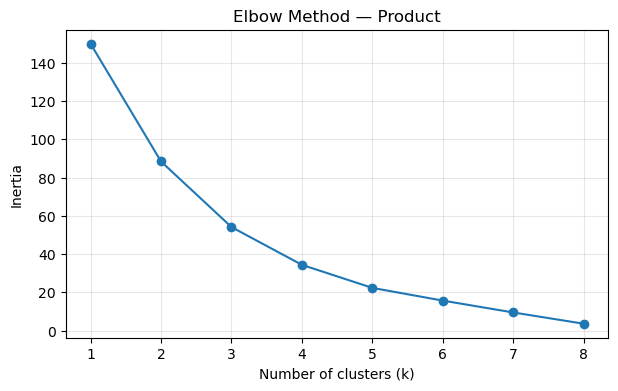

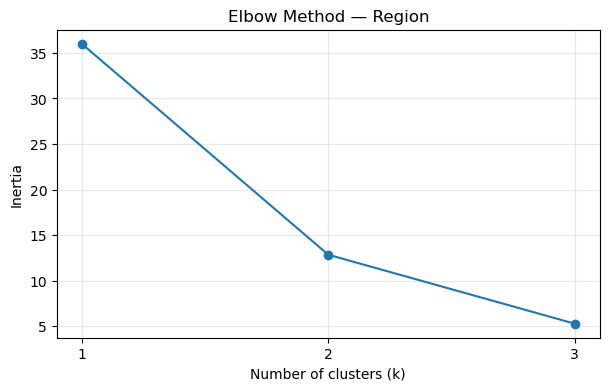

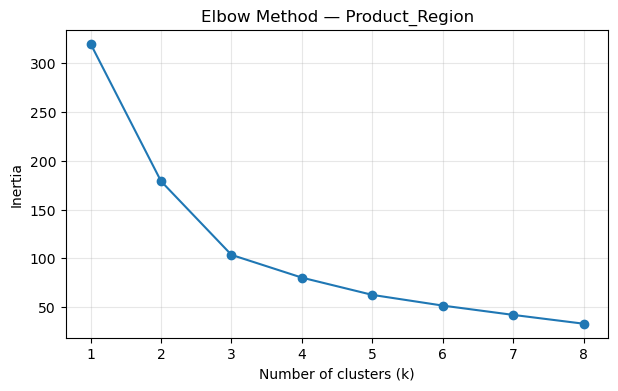

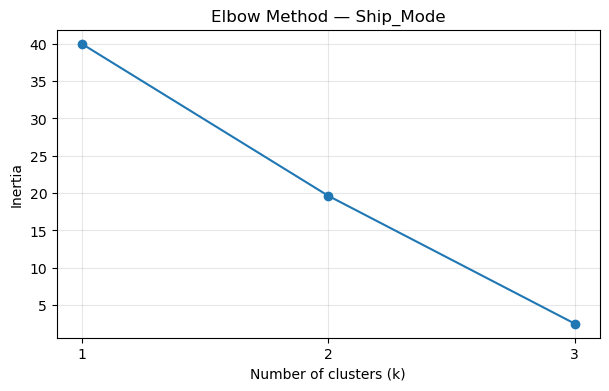

Elbow evaluation completed.


In [26]:
#Elbow method
#The elbow method is diagnostic only. A small number of groups—especially regions and ship modes—can make its results unstable.
# Evaluate KMeans inertia across candidate cluster counts

elbow_results = {}

for name, X_scaled in scaled_matrices.items():

    n_samples = X_scaled.shape[0]
    max_k = min(8, n_samples - 1)

    if max_k < 2:
        print(f"Skipping {name}: insufficient observations.")
        continue

    inertias = []

    for k in range(1, max_k + 1):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )
        model.fit(X_scaled)
        inertias.append(model.inertia_)

    elbow_results[name] = {
        "k_values": list(range(1, max_k + 1)),
        "inertias": inertias
    }

    plt.figure(figsize=(7, 4))
    plt.plot(
        range(1, max_k + 1),
        inertias,
        marker="o"
    )
    plt.title(f"Elbow Method — {name}")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Inertia")
    plt.xticks(range(1, max_k + 1))
    plt.grid(True, alpha=0.3)

    plt.savefig(
        os.path.join(FIGURES_DIR, f"Clustering_Elbow_{name}.png"),
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

print("Elbow evaluation completed.")

In [28]:
#Silhouette score
#A positive score alone does not prove that clusters are meaningful.
#We use a conservative threshold and retain the scores for review rather than automatically forcing a solution.
# Calculate silhouette scores for valid candidate cluster counts

silhouette_results = {}
MIN_ACCEPTABLE_SILHOUETTE = 0.10

for name, X_scaled in scaled_matrices.items():

    n_samples = X_scaled.shape[0]

    if n_samples < 3:
        print(f"Skipping {name}: too few observations.")
        continue

    max_k = min(8, n_samples - 1)
    scores = []

    for k in range(2, max_k + 1):

        try:
            model = KMeans(
                n_clusters=k,
                random_state=42,
                n_init=20
            )
            labels = model.fit_predict(X_scaled)

            if len(np.unique(labels)) < 2:
                continue

            score = silhouette_score(X_scaled, labels)

            scores.append({
                "k": k,
                "silhouette": score
            })

        except Exception as error:
            print(f"{name}, k={k}: {error}")

    silhouette_results[name] = scores

    if scores:
        print(f"\n{name}")
        display(pd.DataFrame(scores).sort_values(
            "silhouette", ascending=False
        ))
    else:
        print(f"\n{name}: no valid silhouette result.")

print("\nSilhouette evaluation completed.")


Product


,k,silhouette
2,4,0.527713
1,3,0.502133
3,5,0.471547
5,7,0.464087
4,6,0.445407
6,8,0.437420
0,2,0.435064



Region


,k,silhouette
0,2,0.303721
1,3,0.099880



Product_Region


,k,silhouette
1,3,0.537610
2,4,0.513277
0,2,0.460801
5,7,0.382050
6,8,0.369156
3,5,0.348631
4,6,0.338289



Ship_Mode


,k,silhouette
1,3,0.275573
0,2,0.199226



Silhouette evaluation completed.


In [30]:
#Product clustering
# Assign exploratory clusters to products when the silhouette evidence is adequate

def choose_cluster_count(name):
    scores = silhouette_results.get(name, [])

    if not scores:
        return None

    best = max(scores, key=lambda item: item["silhouette"])

    if best["silhouette"] < MIN_ACCEPTABLE_SILHOUETTE:
        return None

    return best["k"]

def assign_clusters(name, matrix, scaled_data):
    result = matrix.copy()
    k = choose_cluster_count(name)

    result["Cluster"] = -1

    if k is None:
        result["Cluster_Status"] = "No sufficiently supported solution"
        return result

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(scaled_data)

    if name == "Product_Region":
        eligible_index = result.index[
            result["Eligible_For_Clustering"]
        ]
        result.loc[eligible_index, "Cluster"] = labels
        result["Cluster_Status"] = np.where(
            result["Eligible_For_Clustering"],
            "Clustered",
            "Below minimum sample threshold"
        )
    else:
        result["Cluster"] = labels
        result["Cluster_Status"] = "Clustered"

    return result

product_clusters = assign_clusters(
    "Product",
    product_matrix,
    scaled_matrices["Product"]
)

product_clusters.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Product_Results.csv"),
    index=False
)

print("Product cluster count:", product_clusters["Cluster"].nunique())
display(product_clusters[
    ["Product Name", "Records", "Sales_Total",
     "Gross_Profit_Total", "Lead_Time_Median", "Cluster"]
].sort_values(["Cluster", "Sales_Total"], ascending=[True, False]))

Product cluster count: 4


,Product Name,Records,Sales_Total,Gross_Profit_Total,Lead_Time_Median,Cluster
6,Lickable Wallpaper,94,7860.00,3930.00,1274.0,0
0,Everlasting Gobstopper,3,130.00,104.00,1273.0,0
4,Kazookles,96,1205.75,92.75,1273.0,1
14,Wonka Gum,120,597.50,310.70,1273.5,1
1,Fizzy Lifting Drinks,6,78.75,47.25,1274.0,1
8,SweeTARTS,10,61.50,28.70,1274.0,1
5,Laffy Taffy,10,53.73,33.48,1275.0,1
7,Nerds,4,15.00,7.00,1274.0,1
2,Fun Dip,3,12.00,4.80,1272.0,1
3,Hair Toffee,4,76.50,59.50,1455.0,2


In [32]:
#Region clustering
#There are only four regions in this dataset.
#Any region clusters must therefore be treated as exploratory and not as strong evidence of general regional patterns.
# Assign exploratory destination-performance clusters to regions

region_clusters = assign_clusters(
    "Region",
    region_matrix,
    scaled_matrices["Region"]
)

region_clusters.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Region_Results.csv"),
    index=False
)

print("Number of regions:", len(region_clusters))
print("Region clustering result:")
display(region_clusters[
    ["Region", "Records", "Sales_Total",
     "Gross_Profit_Total", "Lead_Time_Median",
     "Cluster", "Cluster_Status"]
])

print(
    "\nInterpretation warning: these are destination-performance "
    "groups, not traffic or physical-route clusters."
)

Number of regions: 4
Region clustering result:


,Region,Records,Sales_Total,Gross_Profit_Total,Lead_Time_Median,Cluster,Cluster_Status
0,Atlantic,2986,41197.24,26973.70,1274.0,1,Clustered
1,Gulf,1620,22247.26,14700.67,1274.0,0,Clustered
2,Interior,2335,32037.60,21282.49,1274.0,0,Clustered
3,Pacific,3253,46301.53,30485.94,1274.0,1,Clustered



Interpretation warning: these are destination-performance groups, not traffic or physical-route clusters.


In [34]:
#Product-region clustering
# Assign clusters to sufficiently sampled product-region combinations

product_region_clusters = assign_clusters(
    "Product_Region",
    product_region_matrix,
    scaled_matrices["Product_Region"]
)

product_region_clusters.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Product_Region_Results.csv"),
    index=False
)

print("Product-region clustering summary:")
print(
    product_region_clusters["Cluster_Status"].value_counts(
        dropna=False
    )
)

display(product_region_clusters.sort_values(
    ["Cluster", "Lead_Time_Median"],
    ascending=[True, False]
).head(20))

Product-region clustering summary:
Cluster_Status
Clustered                         32
Below minimum sample threshold    21
Name: count, dtype: int64


,Product Name,Region,Records,Unique_Orders,Sales_Total,Sales_Mean,Units_Total,Units_Mean,Gross_Profit_Total,Gross_Profit_Mean,...,Cost_Mean,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std,Profit_Margin_Pct,Sales_Per_Unit,Gross_Profit_Per_Unit,Eligible_For_Clustering,Cluster,Cluster_Status
1,Everlasting Gobstopper,Interior,1,1,30.00,30.000000,3,3.000000,24.00,24.000000,...,6.000,1641.0,1641.000000,NaN,80.000000,10.00,8.00,False,-1,Below minimum sample threshold
10,Hair Toffee,Atlantic,1,1,22.50,22.500000,5,5.000000,17.50,17.500000,...,5.000,1639.0,1639.000000,NaN,77.777778,4.50,3.50,False,-1,Below minimum sample threshold
20,Laffy Taffy,Pacific,1,1,1.99,1.990000,1,1.000000,1.24,1.240000,...,0.750,1638.0,1638.000000,NaN,62.311558,1.99,1.24,False,-1,Below minimum sample threshold
28,SweeTARTS,Pacific,1,1,6.00,6.000000,4,4.000000,2.80,2.800000,...,3.200,1638.0,1638.000000,NaN,46.666667,1.50,0.70,False,-1,Below minimum sample threshold
11,Hair Toffee,Gulf,1,1,9.00,9.000000,2,2.000000,7.00,7.000000,...,2.000,1635.0,1635.000000,NaN,77.777778,4.50,3.50,False,-1,Below minimum sample threshold
3,Fizzy Lifting Drinks,Atlantic,2,2,33.75,16.875000,9,4.500000,20.25,10.125000,...,6.750,1455.5,1455.500000,256.679762,60.000000,3.75,2.25,False,-1,Below minimum sample threshold
17,Laffy Taffy,Atlantic,6,6,27.86,4.643333,14,2.333333,17.36,2.893333,...,1.750,1455.0,1456.166667,200.667303,62.311558,1.99,1.24,False,-1,Below minimum sample threshold
7,Fun Dip,Atlantic,1,1,6.00,6.000000,4,4.000000,2.40,2.400000,...,3.600,1275.0,1275.000000,NaN,40.000000,1.50,0.60,False,-1,Below minimum sample threshold
26,SweeTARTS,Atlantic,5,5,36.00,7.200000,24,4.800000,16.80,3.360000,...,3.840,1275.0,1347.600000,305.501718,46.666667,1.50,0.70,False,-1,Below minimum sample threshold
6,Fizzy Lifting Drinks,Pacific,1,1,11.25,11.250000,3,3.000000,6.75,6.750000,...,4.500,1274.0,1274.000000,NaN,60.000000,3.75,2.25,False,-1,Below minimum sample threshold


In [36]:
#Ship mode performance groups
#There are only four ship-mode categories, so the results are descriptive and highly limited by sample size.
# Assign exploratory performance groups to shipping modes

ship_mode_clusters = assign_clusters(
    "Ship_Mode",
    ship_mode_matrix,
    scaled_matrices["Ship_Mode"]
)

ship_mode_clusters.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Ship_Mode_Results.csv"),
    index=False
)

print("Ship-mode clustering result:")
display(ship_mode_clusters[
    ["Ship Mode", "Records", "Sales_Total",
     "Gross_Profit_Total", "Lead_Time_Median",
     "Cluster", "Cluster_Status"]
])

print(
    "\nThese are shipping-mode performance groups, "
    "not physical route classifications."
)

Ship-mode clustering result:


,Ship Mode,Records,Sales_Total,Gross_Profit_Total,Lead_Time_Median,Cluster,Cluster_Status
0,First Class,1548,21319.39,14011.09,1272.0,2,Clustered
1,Same Day,547,7113.67,4700.73,1269.0,0,Clustered
2,Second Class,1979,27860.22,18306.52,1273.0,2,Clustered
3,Standard Class,6120,85490.35,56424.46,1274.0,1,Clustered



These are shipping-mode performance groups, not physical route classifications.


In [38]:
#Identify slow product-region-mode combinations
#This is a ranking and screening exercise, not a clustering claim. The minimum sample threshold helps prevent very small groups from dominating the results.
# Identify slower product-region-ship-mode combinations with adequate sample sizes

MIN_SLOW_GROUP_RECORDS = 10

slow_combinations = df_cluster.groupby(
    ["Product Name", "Region", "Ship Mode"],
    dropna=False
).agg(
    Records=("Order ID", "size"),
    Unique_Orders=("Order ID", "nunique"),
    Lead_Time_Median=("Lead_Time_Days", "median"),
    Lead_Time_Mean=("Lead_Time_Days", "mean"),
    Lead_Time_Std=("Lead_Time_Days", "std"),
    Sales_Total=("Sales", "sum"),
    Gross_Profit_Total=("Gross Profit", "sum")
).reset_index()

slow_combinations["Eligible_For_Ranking"] = (
    slow_combinations["Records"] >= MIN_SLOW_GROUP_RECORDS
)

slow_combinations["Lead_Time_Std"] = (
    slow_combinations["Lead_Time_Std"].fillna(0)
)

slow_combinations = slow_combinations.sort_values(
    ["Eligible_For_Ranking", "Lead_Time_Median"],
    ascending=[False, False]
)

slow_combinations.to_csv(
    os.path.join(PROCESSED_DIR, "Clustering_Slow_Combinations.csv"),
    index=False
)

print("Eligible groups:", int(
    slow_combinations["Eligible_For_Ranking"].sum()
))
print("Groups below threshold:", int(
    (~slow_combinations["Eligible_For_Ranking"]).sum()
))

display(
    slow_combinations[
        slow_combinations["Eligible_For_Ranking"]
    ].head(20)
)

print(
    "\nCaution: the derived lead-time values are unusually long. "
    "These rankings describe the date-derived measure, not verified "
    "physical transit duration."
)

Eligible groups: 88
Groups below threshold: 66


,Product Name,Region,Ship Mode,Records,Unique_Orders,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std,Sales_Total,Gross_Profit_Total,Eligible_For_Ranking
95,Wonka Bar - Nutty Crunch Surprise,Gulf,Same Day,15,12,1635.0,1439.866667,234.054593,237.32,169.32,True
119,Wonka Bar - Triple Dazzle Caramel,Pacific,Same Day,45,36,1634.0,1407.488889,261.962751,693.75,453.25,True
40,Lickable Wallpaper,Atlantic,Standard Class,19,18,1275.0,1351.105263,287.865496,1520.00,760.00,True
51,Lickable Wallpaper,Pacific,Standard Class,19,19,1275.0,1293.842105,285.105490,1660.00,830.00,True
93,Wonka Bar - Nutty Crunch Surprise,Atlantic,Standard Class,287,243,1275.0,1371.052265,244.493041,3657.52,2609.52,True
113,Wonka Bar - Triple Dazzle Caramel,Gulf,Standard Class,213,166,1275.0,1339.413146,242.357132,2943.75,1923.25,True
137,Wonka Bar -Scrumdiddlyumptious,Pacific,Standard Class,372,314,1275.0,1336.163978,265.864663,5025.60,3490.00,True
141,Wonka Gum,Atlantic,Standard Class,25,24,1275.0,1317.880000,285.489685,143.75,74.75,True
145,Wonka Gum,Gulf,Standard Class,12,12,1274.5,1304.750000,328.995199,71.25,37.05,True
19,Kazookles,Atlantic,Standard Class,22,21,1274.0,1307.500000,274.411882,276.25,21.25,True



Caution: the derived lead-time values are unusually long. These rankings describe the date-derived measure, not verified physical transit duration.


In [40]:
#Cluster profiles
# Profile the measured commercial and lead-time characteristics of each cluster

clustered_tables = {
    "Product": product_clusters,
    "Region": region_clusters,
    "Product_Region": product_region_clusters,
    "Ship_Mode": ship_mode_clusters
}

profile_features = [
    "Records",
    "Sales_Total",
    "Units_Total",
    "Gross_Profit_Total",
    "Cost_Total",
    "Profit_Margin_Pct",
    "Lead_Time_Median",
    "Lead_Time_Mean",
    "Lead_Time_Std"
]

cluster_profiles = {}

for name, result in clustered_tables.items():

    clustered_only = result[result["Cluster"] >= 0].copy()

    if clustered_only.empty:
        print(f"{name}: no supported clusters to profile.")
        continue

    available_features = [
        c for c in profile_features if c in clustered_only.columns
    ]

    profile = clustered_only.groupby("Cluster")[
        available_features
    ].mean().round(2)

    cluster_profiles[name] = profile

    print(f"\n{name} cluster profile")
    display(profile)

    profile.to_csv(
        os.path.join(
            PROCESSED_DIR,
            f"Clustering_{name}_Cluster_Profiles.csv"
        )
    )

print("\nCluster profiling completed.")


Product cluster profile


,Records,Sales_Total,Units_Total,Gross_Profit_Total,Cost_Total,Profit_Margin_Pct,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std
Cluster,,,,,,,,,
0,48.50,3995.00,203.00,2017.00,1978.00,65.00,1273.50,1366.90,250.90
1,35.57,289.18,136.57,74.95,214.22,45.05,1273.64,1309.47,256.58
2,4.00,76.50,17.00,59.50,17.00,77.78,1455.00,1455.25,209.88
3,1968.80,26338.58,7455.00,17764.92,8573.66,67.54,1274.00,1321.25,261.86



Region cluster profile


,Records,Sales_Total,Units_Total,Gross_Profit_Total,Cost_Total,Profit_Margin_Pct,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std
Cluster,,,,,,,,,
0,1977.5,27142.43,7514.5,17991.58,9150.85,66.25,1274.0,1317.23,263.71
1,3119.5,43749.38,11812.5,28729.82,15019.56,65.66,1274.0,1322.47,261.51



Product_Region cluster profile


,Records,Sales_Total,Units_Total,Gross_Profit_Total,Cost_Total,Profit_Margin_Pct,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std
Cluster,,,,,,,,,
0,492.2,6584.64,1863.75,4441.23,2143.41,67.54,1273.75,1320.40,261.76
1,27.0,225.41,106.12,50.43,174.98,29.85,1273.38,1283.76,279.99
2,23.5,1965.00,98.25,982.50,982.50,50.00,1274.00,1331.08,301.83



Ship_Mode cluster profile


,Records,Sales_Total,Units_Total,Gross_Profit_Total,Cost_Total,Profit_Margin_Pct,Lead_Time_Median,Lead_Time_Mean,Lead_Time_Std
Cluster,,,,,,,,,
0,547.0,7113.67,1975.0,4700.73,2412.94,66.08,1269.0,1333.44,253.81
1,6120.0,85490.35,23409.0,56424.46,29065.89,66.00,1274.0,1314.33,262.40
2,1763.5,24589.80,6635.0,16158.80,8431.00,65.71,1272.5,1331.06,263.72



Cluster profiling completed.


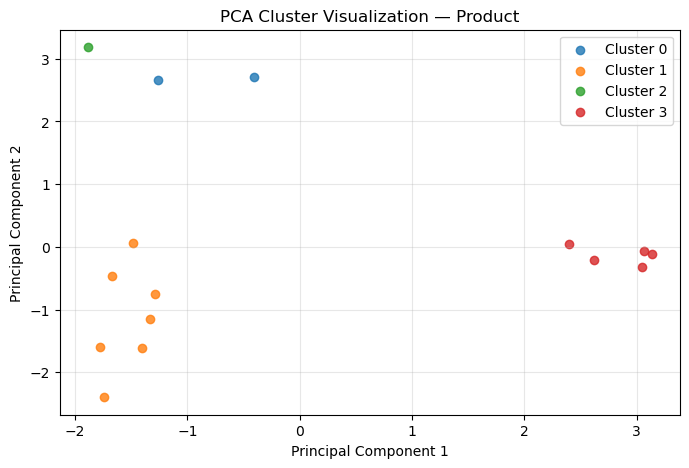

Product observations plotted: 15
Features used: ['Sales_Total', 'Units_Total', 'Gross_Profit_Total', 'Cost_Total', 'Profit_Margin_Pct', 'Sales_Per_Unit', 'Gross_Profit_Per_Unit', 'Lead_Time_Median', 'Lead_Time_Mean', 'Lead_Time_Std']
Explained variance: 0.6717


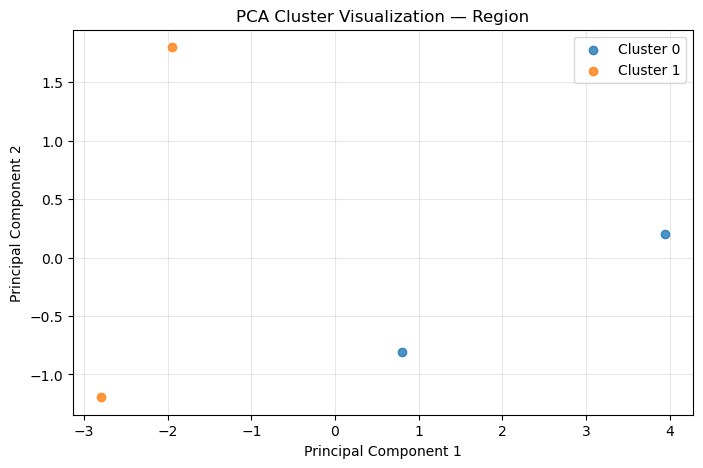

Region observations plotted: 4
Features used: ['Sales_Total', 'Units_Total', 'Gross_Profit_Total', 'Cost_Total', 'Profit_Margin_Pct', 'Sales_Per_Unit', 'Gross_Profit_Per_Unit', 'Lead_Time_Mean', 'Lead_Time_Std']
Explained variance: 0.919


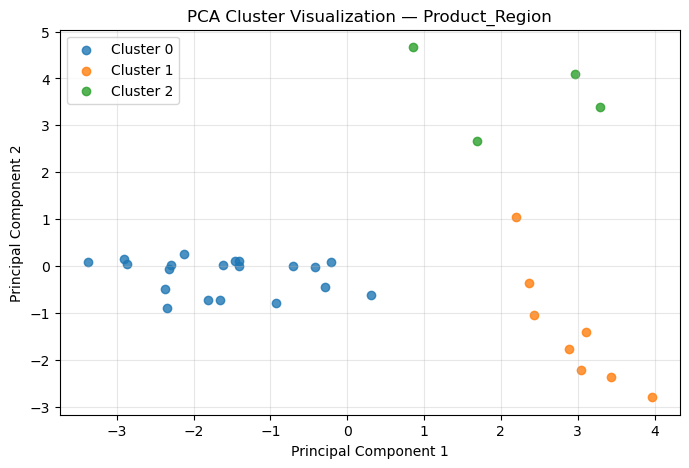

Product_Region observations plotted: 32
Features used: ['Sales_Total', 'Units_Total', 'Gross_Profit_Total', 'Cost_Total', 'Profit_Margin_Pct', 'Sales_Per_Unit', 'Gross_Profit_Per_Unit', 'Lead_Time_Median', 'Lead_Time_Mean', 'Lead_Time_Std']
Explained variance: 0.7855


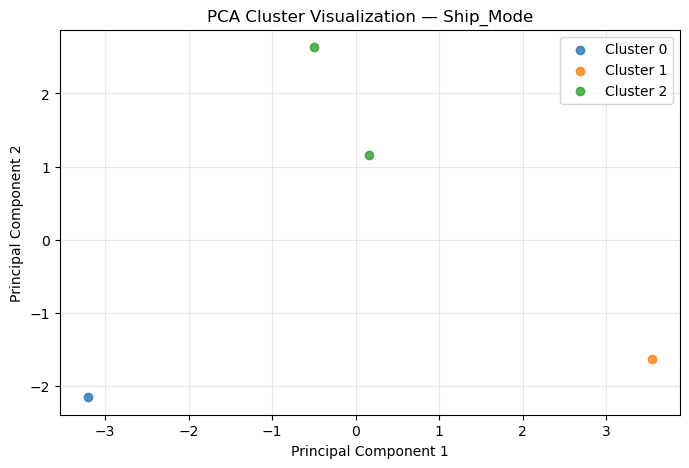

Ship_Mode observations plotted: 4
Features used: ['Sales_Total', 'Units_Total', 'Gross_Profit_Total', 'Cost_Total', 'Profit_Margin_Pct', 'Sales_Per_Unit', 'Gross_Profit_Per_Unit', 'Lead_Time_Median', 'Lead_Time_Mean', 'Lead_Time_Std']
Explained variance: 0.9674
SUCCESS: PCA cluster visualizations completed.


In [50]:
# Visualize cluster assignments using correctly aligned PCA observations

for name, result in clustered_tables.items():

    clustered_only = result[result["Cluster"] >= 0].copy()

    if len(clustered_only) < 3:
        print(f"Skipping PCA for {name}: insufficient observations.")
        continue

    feature_columns = clean_feature_matrices[name].columns.tolist()

    aligned_features = clean_feature_matrices[name].loc[
        clustered_only.index, feature_columns
    ]

    X_plot = scalers[name].transform(aligned_features)

    pca = PCA(n_components=2, random_state=42)
    coordinates = pca.fit_transform(X_plot)

    plot_data = pd.DataFrame({
        "PC1": coordinates[:, 0],
        "PC2": coordinates[:, 1],
        "Cluster": clustered_only["Cluster"].astype(str).values
    })

    plt.figure(figsize=(8, 5))

    for cluster_label, group in plot_data.groupby("Cluster"):
        plt.scatter(
            group["PC1"],
            group["PC2"],
            label=f"Cluster {cluster_label}",
            alpha=0.8
        )

    plt.title(f"PCA Cluster Visualization — {name}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.savefig(
        os.path.join(FIGURES_DIR, f"Clustering_PCA_{name}.png"),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(f"{name} observations plotted: {len(plot_data)}")
    print(f"Features used: {feature_columns}")
    print(
        "Explained variance:",
        round(pca.explained_variance_ratio_.sum(), 4)
    )

print("SUCCESS: PCA cluster visualizations completed.")

In [48]:
#Interpret clusters and save business findings
#This final cell generates a findings report from the actual cluster profiles and validation results. 
#It does not invent cluster labels or assume that a cluster is inherently good or bad
# Generate evidence-based clustering findings and verify source-data integrity

report_lines = [
    "NASSAU CANDY DISTRIBUTOR — CLUSTERING ANALYSIS",
    "",
    "OBJECTIVE",
    "Identify exploratory product, destination-performance, "
    "product-region, and ship-mode performance groups.",
    "",
    "IMPORTANT LIMITATIONS",
    "- Clusters are descriptive, not causal.",
    "- Region groups are based on only four regions.",
    "- Ship-mode groups are based on only four ship-mode categories.",
    "- Product-region combinations below the minimum record threshold "
    "were not included in clustering.",
    "- Ship Date was not used as a clustering feature.",
    "- Lead-time statistics are derived from the supplied dates. "
    "The unusually long values are not verified transit durations.",
    "- These clusters do not represent actual factory assignments, "
    "physical routes, traffic congestion, or transport savings.",
    ""
]

for name, result in clustered_tables.items():

    report_lines.append(f"{name.upper()} RESULTS")

    if "Cluster_Status" in result.columns:
        report_lines.append(
            "Status counts: "
            + str(result["Cluster_Status"].value_counts().to_dict())
        )

    if name in cluster_profiles:
        report_lines.append("Cluster profile averages:")
        report_lines.append(
            cluster_profiles[name].to_string()
        )
    else:
        report_lines.append(
            "No sufficiently supported cluster profile was produced."
        )

    scores = silhouette_results.get(name, [])

    if scores:
        best = max(scores, key=lambda item: item["silhouette"])
        report_lines.append(
            f"Best evaluated silhouette: {best['silhouette']:.4f} "
            f"at k={best['k']}."
        )
    else:
        report_lines.append("No valid silhouette score was available.")

    report_lines.append("")

report_lines.extend([
    "SLOW COMBINATION SCREENING",
    f"Minimum records required: {MIN_SLOW_GROUP_RECORDS}",
    "Slow combinations are ranked using median derived lead time "
    "and must be interpreted with the date-semantics caveat.",
    "",
    "BUSINESS INTERPRETATION GUIDANCE",
    "- Review high-sales and high-profit product segments for "
    "commercial importance.",
    "- Review low-margin segments separately from high-volume segments.",
    "- Investigate destination groups with higher derived lead-time "
    "medians, while validating the date meaning first.",
    "- Use small-sample groups as investigation leads, not firm conclusions.",
    "- Do not make factory reassignment or transport-savings claims "
    "from these clusters alone."
])

report_text = "\n".join(report_lines)

REPORT_FILE = os.path.join(
    PROJECT_ROOT, "reports",
    "Clustering_Analysis_Findings.txt"
)

with open(REPORT_FILE, "w", encoding="utf-8") as file:
    file.write(report_text)

print(report_text)

# Verify the original columns and their values remain unchanged.
integrity_check = df_cluster[original_columns].equals(
    original_snapshot
)

print("\nINTEGRITY CHECK")
print("Original source columns unchanged:", integrity_check)
print("Original source row count:", len(df_cluster))
print("Processed input row count:", len(pd.read_csv(INPUT_FILE)))
print("Findings report saved:", os.path.exists(REPORT_FILE))

if not integrity_check:
    raise AssertionError("Original source columns were modified.")

print("\nSUCCESS: Clustering analysis workflow completed.")

NASSAU CANDY DISTRIBUTOR — CLUSTERING ANALYSIS

OBJECTIVE
Identify exploratory product, destination-performance, product-region, and ship-mode performance groups.

IMPORTANT LIMITATIONS
- Clusters are descriptive, not causal.
- Region groups are based on only four regions.
- Ship-mode groups are based on only four ship-mode categories.
- Product-region combinations below the minimum record threshold were not included in clustering.
- Ship Date was not used as a clustering feature.
- Lead-time statistics are derived from the supplied dates. The unusually long values are not verified transit durations.
- These clusters do not represent actual factory assignments, physical routes, traffic congestion, or transport savings.

PRODUCT RESULTS
Status counts: {'Clustered': 15}
Cluster profile averages:
         Records  Sales_Total  Units_Total  Gross_Profit_Total  Cost_Total  Profit_Margin_Pct  Lead_Time_Median  Lead_Time_Mean  Lead_Time_Std
Cluster                                             